# Two animals, four haplotypes
Does the first study hold in a second animal?

Notebook 01 used one animal, `IMCG_204112`, with its two haplotypes P and M. The screening of 20 public assemblies (notebook 02) found one more animal whose centromeres are resolved about as well: a Kiko × Saanen F1 female (`KikoP` and `SaanenM`). This notebook repeats the tests of 01 on it and puts the two animals side by side.

| Animal | Haplotypes | Notes |
|---|---|---|
| IMCG_204112 | P, M | cashmere goat, male; P has the Y, M has the X |
| Kiko × Saanen | KikoP, SaanenM | F1 female; each haplotype comes from a different breed |

What is compared:
1. H1, scaling of the centromere with chromosome size, in each haplotype and pooled.
2. H3, difference between the two haplotypes of an animal, in the centromere and in the rest of the chromosome.
3. How much a centromere changes within an animal (between its two haplotypes) against between animals.

A centromere is used only if it is complete (detected, no gap within 100 kb) and not flagged `low_satellite`. These criteria do not use T2T-goat2.0 as a yardstick, so the comparison between animals is not biased by them.

Two animals are not enough to estimate variation between individuals with confidence. The comparison is descriptive.

In [1]:
import os, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

BASE = Path.cwd()
if BASE.name == 'notebooks': BASE = BASE.parent
DATA = BASE/'data'; PER = DATA/'screening'/'per_assembly'
OUT = DATA/'two_animals'; FIG = DATA/'figures'; OUT.mkdir(exist_ok=True, parents=True); FIG.mkdir(exist_ok=True)
SEED = 20241013; KINDS_SAT = ['SatI', 'SatII', 'SatIII']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

m = pd.read_csv(DATA/'centromeres_master.csv'); m = m[m.hap.isin(['P', 'M']) & (m.kind != 'Y')].copy()
m['hap'] = m.hap.map({'P': 'IMCG_P', 'M': 'IMCG_M'})
ks = pd.concat([pd.read_csv(PER/h/'centromeres.csv') for h in ('KikoP', 'SaanenM')], ignore_index=True)
D = pd.concat([m, ks], ignore_index=True, sort=False)
D['animal'] = D.hap.map({'IMCG_P': 'IMCG', 'IMCG_M': 'IMCG', 'KikoP': 'Kiko×Saanen', 'SaanenM': 'Kiko×Saanen'})
D['ok'] = D.complete & ~D.low_satellite & D.cen_len.notna()
D['cen_Mb'] = D.cen_len/1e6; D['rest_Mb'] = (D.length - D.cen_len)/1e6
D['lcen'], D['lrest'] = np.log(D.cen_Mb), np.log(D.rest_Mb)
HAPS = ['IMCG_P', 'IMCG_M', 'KikoP', 'SaanenM']; COL = {'IMCG_P': '#3b6fb6', 'IMCG_M': '#7aa6d8', 'KikoP': '#e08a1e', 'SaanenM': '#f0c27a'}
t = D.groupby('hap').agg(chromosomes=('chr', 'size'), usable=('ok', 'sum'), complete=('complete', 'sum'), low_satellite=('low_satellite', 'sum'), median_cen_Mb=('cen_Mb', 'median'),
                         SatI_Mb=('SatI', lambda x: x.sum()/1e6), SatII_Mb=('SatII', lambda x: x.sum()/1e6), SatIII_Mb=('SatIII', lambda x: x.sum()/1e6)).loc[HAPS].round(2)
t.to_csv(OUT/'haplotypes.csv'); display(t)

,chromosomes,usable,complete,low_satellite,median_cen_Mb,SatI_Mb,SatII_Mb,SatIII_Mb
hap,,,,,,,,
IMCG_P,29,20,20,0,7.29,109.34,24.71,7.34
IMCG_M,30,22,25,3,5.91,100.79,18.76,4.90
KikoP,30,30,30,0,7.83,131.49,29.46,5.22
SaanenM,30,29,29,0,7.71,127.38,31.47,6.11


## H1 · Scaling in each haplotype and pooled
Same model as in the first study: `ln(centromere) = a + b · ln(remaining length)`. The four haplotypes share the same chromosomes, so in the pooled fit the errors are grouped by chromosome. The X is in M, KikoP and SaanenM but not in P, so every fit is also run without it.

In [2]:
rng = np.random.default_rng(SEED)
def fit(df, label, cluster=False):
    n = len(df); X, Y = df.lrest.to_numpy(), df.lcen.to_numpy()
    if cluster: r = smf.ols('lcen ~ lrest', df).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(df.chr)[0]})
    else: r = smf.ols('lcen ~ lrest', df).fit(cov_type='HC3')
    lo, hi = r.conf_int().loc['lrest']
    if cluster:                                    # bootstrap over chromosomes
        ch = df.chr.unique(); bs = []
        for _ in range(3000):
            s = pd.concat([df[df.chr == c] for c in rng.choice(ch, len(ch))]); bs.append(np.polyfit(s.lrest, s.lcen, 1)[0])
    else:
        idx = rng.integers(0, n, (3000, n)); bs = [np.polyfit(X[i], Y[i], 1)[0] for i in idx]
    return dict(model=label, n=n, slope=r.params['lrest'], CI95=f'[{lo:.2f}, {hi:.2f}]', CI95_boot=f'[{np.percentile(bs, 2.5):.2f}, {np.percentile(bs, 97.5):.2f}]', p_slope_0=r.pvalues['lrest'], R2=r.rsquared)
U = D[D.ok]; rows = []
for h in HAPS:
    rows.append(fit(U[U.hap == h], f'{h}'))
    rows.append(fit(U[(U.hap == h) & (U.kind == 'autosome')], f'{h}, without X'))
for a in ('IMCG', 'Kiko×Saanen'):
    rows.append(fit(U[(U.animal == a) & (U.kind == 'autosome')], f'{a}, both haplotypes, autosomes', cluster=True))
rows.append(fit(U, 'All four haplotypes', cluster=True)); rows.append(fit(U[U.kind == 'autosome'], 'All four haplotypes, autosomes only', cluster=True))
h1 = pd.DataFrame(rows); h1.to_csv(OUT/'H1_two_animals.csv', index=False); display(h1.round(3))
# does the slope differ between the two animals?
au = U[U.kind == 'autosome']; mi = smf.ols('lcen ~ lrest * C(animal)', au).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(au.chr)[0]})
term = [k for k in mi.params.index if k.startswith('lrest:')][0]
print(f'Slope difference between animals (autosomes): {mi.params[term]:.2f}, CI95 [{mi.conf_int().loc[term, 0]:.2f}, {mi.conf_int().loc[term, 1]:.2f}], p = {mi.pvalues[term]:.2f}')

,model,n,slope,CI95,CI95_boot,p_slope_0,R2
0,IMCG_P,20,0.194,"[-0.11, 0.50]","[-0.18, 0.46]",0.207,0.035
1,"IMCG_P, without X",20,0.194,"[-0.11, 0.50]","[-0.17, 0.47]",0.207,0.035
2,IMCG_M,22,-0.018,"[-0.92, 0.88]","[-0.85, 0.78]",0.969,0.000
3,"IMCG_M, without X",21,0.355,"[-0.16, 0.87]","[-0.05, 0.97]",0.174,0.059
4,KikoP,30,-0.011,"[-0.74, 0.72]","[-0.77, 0.51]",0.976,0.000
5,"KikoP, without X",29,0.337,"[0.11, 0.57]","[0.11, 0.57]",0.004,0.285
6,SaanenM,29,-0.064,"[-0.76, 0.63]","[-0.73, 0.52]",0.857,0.003
7,"SaanenM, without X",28,0.262,"[-0.06, 0.58]","[0.01, 0.60]",0.112,0.119
8,"IMCG, both haplotypes, autosomes",41,0.300,"[0.01, 0.59]","[0.01, 0.64]",0.044,0.051
9,"Kiko×Saanen, both haplotypes, autosomes",57,0.301,"[0.08, 0.53]","[0.10, 0.55]",0.009,0.186


Slope difference between animals (autosomes): 0.00, CI95 [-0.32, 0.32], p = 1.00


## H3 · Do the two homologs differ more in the centromere than in the rest?
Same as before. For each autosome that is usable in both haplotypes of an animal we take the absolute difference in the centromere and in the rest of the chromosome, on a relative scale (`|ln(P/M)|`) and an absolute one (Mb). The test is a paired one-sided permutation test (sign flips within each pair). The pooled test puts the pairs of both animals together.

In [3]:
def pairs(a, b, animal):
    x, y = U[(U.hap == a) & (U.kind == 'autosome')].set_index('chr'), U[(U.hap == b) & (U.kind == 'autosome')].set_index('chr')
    j = x[['length', 'cen_len']].join(y[['length', 'cen_len']], lsuffix='_a', rsuffix='_b', how='inner')
    j['rest_a'], j['rest_b'] = j.length_a - j.cen_len_a, j.length_b - j.cen_len_b
    j['rel_cen'], j['rel_rest'] = np.log(j.cen_len_a/j.cen_len_b).abs(), np.log(j.rest_a/j.rest_b).abs()
    j['abs_cen'], j['abs_rest'] = (j.cen_len_a - j.cen_len_b).abs()/1e6, (j.rest_a - j.rest_b).abs()/1e6
    j['animal'] = animal; return j.reset_index()
PA, PB = pairs('IMCG_P', 'IMCG_M', 'IMCG'), pairs('KikoP', 'SaanenM', 'Kiko×Saanen'); PP = pd.concat([PA, PB], ignore_index=True)
def test(df, a, b, label):
    x, y = df[a].to_numpy(), df[b].to_numpy(); n = len(x)
    pm = stats.permutation_test((x, y), lambda u, v, axis: np.mean(u - v, axis=axis), permutation_type='samples', alternative='greater', n_resamples=np.inf if n <= 18 else 200_000, vectorized=True, random_state=SEED)
    bs = np.median((x - y)[np.random.default_rng(SEED).integers(0, n, (5000, n))], axis=1)
    return dict(comparison=label, n=n, median_centromere=np.median(x), median_rest=np.median(y), CI95_median_diff=f'[{np.percentile(bs, 2.5):.3g}, {np.percentile(bs, 97.5):.3g}]', p_permutation=pm.pvalue)
rows = []
for name, df in (('IMCG (P vs M)', PA), ('Kiko×Saanen (KikoP vs SaanenM)', PB), ('Both animals pooled', PP)):
    rows.append(test(df, 'abs_cen', 'abs_rest', f'{name}, absolute (Mb)')); rows.append(test(df, 'rel_cen', 'rel_rest', f'{name}, relative'))
h3 = pd.DataFrame(rows); h3.to_csv(OUT/'H3_two_animals.csv', index=False); PP.to_csv(OUT/'H3_pairs.csv', index=False); display(h3.round(4))
fam = {a: pd.Series({k: ((U[(U.hap == h1_) & (U.kind == 'autosome')].set_index('chr')[k] - U[(U.hap == h2_) & (U.kind == 'autosome')].set_index('chr')[k]).abs().dropna()/1e6).median() for k in KINDS_SAT}) for a, (h1_, h2_) in {'IMCG': ('IMCG_P', 'IMCG_M'), 'Kiko×Saanen': ('KikoP', 'SaanenM')}.items()}
print('Median difference between haplotypes by family (Mb):'); display(pd.DataFrame(fam).round(2))

,comparison,n,median_centromere,median_rest,CI95_median_diff,p_permutation
0,"IMCG (P vs M), absolute (Mb)",16,2.6712,0.1069,"[1.11, 3.57]",0.0000
1,"IMCG (P vs M), relative",16,0.3709,0.0012,"[0.147, 0.606]",0.0000
2,"Kiko×Saanen (KikoP vs SaanenM), absolute (Mb)",28,1.1708,0.1751,"[0.531, 1.39]",0.0301
3,"Kiko×Saanen (KikoP vs SaanenM), relative",28,0.1645,0.0020,"[0.116, 0.235]",0.0000
4,"Both animals pooled, absolute (Mb)",44,1.2829,0.1372,"[0.683, 1.94]",0.0001
5,"Both animals pooled, relative",44,0.1734,0.0015,"[0.147, 0.309]",0.0000


Median difference between haplotypes by family (Mb):


,IMCG,Kiko×Saanen
SatI,1.78,1.41
SatII,0.23,0.15
SatIII,0.10,0.04


## Within an animal against between animals
For every chromosome that is usable in all four haplotypes we compare the centromere length of each pair of haplotypes with `|ln(a/b)|`. Pairs within an animal are P with M and KikoP with SaanenM. Pairs between animals are the four crossed ones. If the animals were very different from each other, the crossed pairs would differ more than the pairs within an animal. Because the two haplotypes of Kiko × Saanen come from different breeds, that pair is a mixture of individual and breed.

In [4]:
W4 = U[U.kind == 'autosome'].pivot(index='chr', columns='hap', values='cen_len').dropna()[HAPS]
print('Autosomes usable in all four haplotypes:', len(W4))
from itertools import combinations
rows = []
for a, b in combinations(HAPS, 2):
    kind = 'within IMCG' if {a, b} == {'IMCG_P', 'IMCG_M'} else 'within Kiko×Saanen' if {a, b} == {'KikoP', 'SaanenM'} else 'between animals'
    rows += [dict(pair=f'{a} / {b}', type=kind, chr=c, d=abs(np.log(W4.loc[c, a]/W4.loc[c, b]))) for c in W4.index]
wb = pd.DataFrame(rows); wb.to_csv(OUT/'within_between.csv', index=False)
s = wb.groupby('type').d.agg(['count', 'median', lambda x: x.quantile(.75)]).rename(columns={'<lambda_0>': 'q75'}).round(3); display(s)
print('Median |ln ratio| by pair:'); display(wb.groupby('pair').d.median().round(3).to_frame())
kw = stats.kruskal(*[g.d.to_numpy() for _, g in wb.groupby('type')]); print(f'Kruskal–Wallis across the three types: p = {kw.pvalue:.3f} (pairs of the same chromosome are not independent, so read it as a guide)')
# same chromosome, same ranking in both animals?
r = stats.spearmanr(W4.IMCG_P if 'IMCG_P' in W4 else W4.iloc[:, 0], W4.KikoP); print(f'Spearman between IMCG_P and KikoP, same chromosome: {r[0]:.2f} (p = {r[1]:.3f})')

Autosomes usable in all four haplotypes: 15


,count,median,q75
type,,,
between animals,60,0.213,0.423
within IMCG,15,0.380,0.683
within Kiko×Saanen,15,0.166,0.300


Median |ln ratio| by pair:


,d
pair,
IMCG_M / KikoP,0.333
IMCG_M / SaanenM,0.242
IMCG_P / IMCG_M,0.380
IMCG_P / KikoP,0.172
IMCG_P / SaanenM,0.169
KikoP / SaanenM,0.166


Kruskal–Wallis across the three types: p = 0.161 (pairs of the same chromosome are not independent, so read it as a guide)
Spearman between IMCG_P and KikoP, same chromosome: 0.49 (p = 0.064)


## Figures

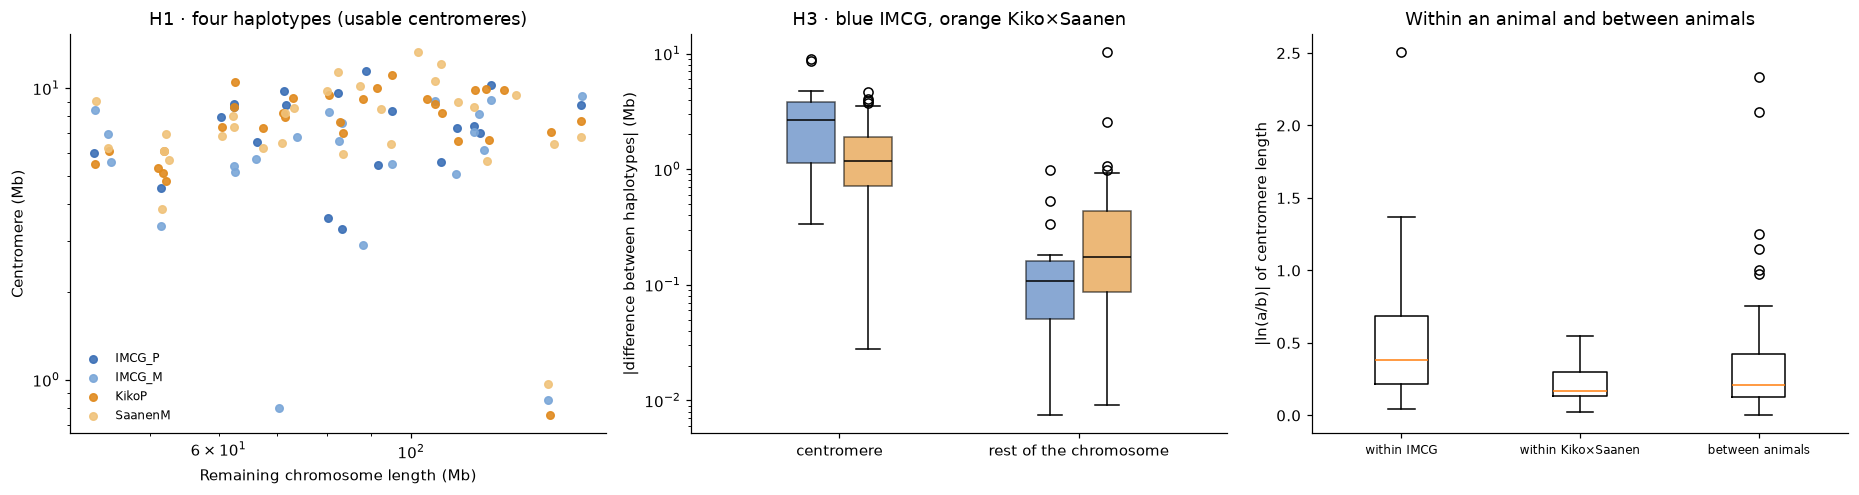

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for h in HAPS:
    g = U[U.hap == h]; ax[0].scatter(g.rest_Mb, g.cen_Mb, s=24, color=COL[h], label=h, alpha=.9)
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('Remaining chromosome length (Mb)'); ax[0].set_ylabel('Centromere (Mb)'); ax[0].legend(frameon=False, fontsize=8); ax[0].set_title('H1 · four haplotypes (usable centromeres)')
for a_, col, off in (('IMCG', '#3b6fb6', -.12), ('Kiko×Saanen', '#e08a1e', .12)):
    d = PP[PP.animal == a_]; ax[1].boxplot([d.abs_cen, d.abs_rest], positions=[1 + off, 2 + off], widths=.2, patch_artist=True, boxprops=dict(facecolor=col, alpha=.6), medianprops=dict(color='k'))
ax[1].set_xticks([1, 2]); ax[1].set_xticklabels(['centromere', 'rest of the chromosome']); ax[1].set_yscale('log'); ax[1].set_ylabel('|difference between haplotypes| (Mb)')
ax[1].set_title('H3 · blue IMCG, orange Kiko×Saanen')
order = ['within IMCG', 'within Kiko×Saanen', 'between animals']
ax[2].boxplot([wb[wb.type == k].d for k in order], showfliers=True); ax[2].set_xticklabels(order, fontsize=8); ax[2].set_ylabel('|ln(a/b)| of centromere length'); ax[2].set_title('Within an animal and between animals')
plt.tight_layout(); plt.savefig(FIG/'two_animals.png', dpi=150); plt.show()

## Centromeres worth a second look
Usable centromeres whose satellite is more than twice or less than half of that of T2T-goat2.0, and chromosomes that were left out because of a gap. This is a list of cases, not a filter.

In [6]:
q = D[D.hap.isin(['KikoP', 'SaanenM'])].copy()
odd = q[(q.sat_vs_T2T > 2) | (q.sat_vs_T2T < 0.5) | (~q.complete) | q.low_satellite][['hap', 'chr', 'cen_len', 'sat_frac', 'n_gaps_cen', 'sat_vs_T2T', 'complete', 'low_satellite']]
odd['cen_len'] = (odd.cen_len/1e6).round(2); display(odd.round(2)); odd.to_csv(OUT/'cases_to_review.csv', index=False)

,hap,chr,cen_len,sat_frac,n_gaps_cen,sat_vs_T2T,complete,low_satellite
72,KikoP,CHI14,11.11,0.81,0,2.16,True,False
93,SaanenM,CHI5,14.97,0.65,1,2.46,False,False
95,SaanenM,CHI7,12.08,0.71,0,2.08,True,False
103,SaanenM,CHI15,11.39,0.60,0,2.16,True,False


## Things to keep in mind when reading these results
The four centromeres listed above were reviewed by hand. They stay in the analysis. This is what the review found, and it should be kept in mind when interpreting H1 and H3.

- Kiko CHI14, Saanen CHI7 and Saanen CHI15 have much more satellite than the same chromosome in the other haplotypes, mostly SatI. In all three the chromosome is longer by about the same amount as the centromere, so the extra sequence is in the assembly and is not a detection error. It could be a real expansion of the array or a duplication made by the assembler. Without long reads from the same animal the two cannot be told apart.
- In Saanen CHI15 the block is inflated by about 3 Mb of spacer between two small satellite islands that were merged. The satellite alone is 6.9 Mb, 2.2 times the value in T2T-goat2.0.
- Saanen CHI5 reaches 14.97 Mb, which is the size of the 15-Mb window, so its block is probably cut and the real centromere is longer. It also has a gap. It is left out as incomplete and does not enter H1 or H3.
- These three chromosomes carry the largest differences between KikoP and SaanenM, so the replication of H3 in the second animal depends on them. The cell below shows how much. Removing them only because their differences are large would be selecting against the hypothesis, so they are kept. The fair reading is that H3 replicates in part in the second animal, and that the replication rests on three chromosomes with large expansions of uncertain origin. Pooled over both animals it is clear either way.
- H1 does not depend on them.

In [7]:
# Sensitivity, for reference only. The results above are the ones that count.
three = ['CHI7', 'CHI14', 'CHI15']
sens = [test(PB, 'abs_cen', 'abs_rest', 'Kiko×Saanen, absolute (Mb), all pairs'),
        test(PB[~PB.chr.isin(three)], 'abs_cen', 'abs_rest', 'Kiko×Saanen, absolute (Mb), without CHI7, CHI14 and CHI15'),
        test(PP, 'abs_cen', 'abs_rest', 'Both animals, absolute (Mb), all pairs'),
        test(PP[~PP.chr.isin(three)], 'abs_cen', 'abs_rest', 'Both animals, absolute (Mb), without CHI7, CHI14 and CHI15')]
display(pd.DataFrame(sens).round(4))
drop = [('KikoP', 'CHI14'), ('SaanenM', 'CHI7'), ('SaanenM', 'CHI15')]
no3 = U[~U.apply(lambda r: (r.hap, r.chr) in drop, axis=1)]
sh1 = pd.DataFrame([fit(U[U.kind == 'autosome'], 'Four haplotypes, autosomes', cluster=True), fit(no3[no3.kind == 'autosome'], 'Four haplotypes, autosomes, without the three centromeres', cluster=True)])
sh1.to_csv(OUT/'sensitivity_three_centromeres.csv', index=False); display(sh1.round(3))

,comparison,n,median_centromere,median_rest,CI95_median_diff,p_permutation
0,"Kiko×Saanen, absolute (Mb), all pairs",28,1.1708,0.1751,"[0.531, 1.39]",0.0301
1,"Kiko×Saanen, absolute (Mb), without CHI7, CHI1...",25,1.0762,0.1296,"[0.427, 1.2]",0.1684
2,"Both animals, absolute (Mb), all pairs",44,1.2829,0.1372,"[0.683, 1.94]",0.0001
3,"Both animals, absolute (Mb), without CHI7, CHI...",39,1.1747,0.1296,"[0.549, 1.53]",0.0005


,model,n,slope,CI95,CI95_boot,p_slope_0,R2
0,"Four haplotypes, autosomes",98,0.295,"[0.10, 0.49]","[0.12, 0.52]",0.002,0.081
1,"Four haplotypes, autosomes, without the three ...",95,0.278,"[0.09, 0.47]","[0.11, 0.49]",0.004,0.075
